# Uncertainty-based query strategies

This notebook compares random querying with two strategies that try to pick the most useful
labels:

- `QueryByCommittee` trains a small committee of regressors per output, with online bagging, and
  queries the outputs on which the committee disagrees the most.
- `ExpectedError` trains a regressor per output to predict the error of the model, and queries
  the outputs on which the model is expected to be the most wrong.

It also shows why these strategies need a budget manager that looks at utilities, and that they
are not guaranteed to beat random querying.

In [1]:
import random

import matplotlib.pyplot as plt
import pandas as pd
from river import datasets, linear_model, metrics, multioutput, neighbors, preprocessing, utils

import fishladder as fl

## A stream where some instances matter more

The stream has two outputs. `smooth` is a simple function of the features. `spike` is zero
everywhere except in a small corner of the feature space, which only about 2% of the instances
fall into. A model can only learn the spike from instances in that corner, so querying them is
much more useful than querying the others.

We use nearest neighbours, both as the model and as the regressor inside the strategies, since it
can represent the spike.

In [2]:
COSTS = {"smooth": 1.0, "spike": 1.0}


def spike_stream(n, seed=0):
    rng = random.Random(seed)
    for _ in range(n):
        x = {"x0": rng.random(), "x1": rng.random()}
        spike = 20.0 if x["x0"] > 0.85 and x["x1"] > 0.85 else 0.0
        yield (
            x,
            {
                "smooth": 3 * x["x0"] + x["x1"] + rng.gauss(0, 0.1),
                "spike": spike + rng.gauss(0, 0.1),
            },
        )


def knn():
    return neighbors.KNNRegressor(n_neighbors=5)


def make_model():
    return multioutput.PerOutputRegressor(knn())


def make_strategies(seed):
    return {
        "random": fl.strategy.RandomPerOutput(p=1.0, seed=seed),
        "committee": fl.strategy.QueryByCommittee(knn(), n_members=5, seed=seed),
        "expected error": fl.strategy.ExpectedError(knn()),
    }

## Why utilities need a threshold

With `RateBudget`, an output is queried as soon as its budget can afford it, as long as its
utility is positive. The size of the utility then hardly matters: any strategy that gives
positive utilities ends up querying the same instances.

In [3]:
def queried(strategy, budget, seed=0):
    log = fl.evaluate.prequential(spike_stream(3000, seed), make_model(), strategy, budget, COSTS)
    return log.to_frame()["queried"]


plain = {
    name: queried(strategy, fl.budget.PerOutput(fl.budget.RateBudget(0.2)))
    for name, strategy in make_strategies(seed=0).items()
}
bool((plain["committee"] == plain["expected error"]).all())

True

Both strategies query exactly the same instances. `VariableThreshold` fixes this. It keeps a
threshold per output: when an output is affordable, it is only queried if its utility reaches the
threshold, which is then raised. Otherwise, the threshold is lowered. The budget is thus saved for
instances whose utility is high compared to recent ones.

In [4]:
def make_budget():
    return fl.budget.VariableThreshold(fl.budget.PerOutput(fl.budget.RateBudget(0.2)))


thresholded = {
    name: queried(strategy, make_budget()) for name, strategy in make_strategies(seed=0).items()
}
bool((thresholded["committee"] == thresholded["expected error"]).all())

False

## Comparing strategies

Each setup spends 0.2 cost units per instance, i.e. it labels about 10% of each output. We run
every strategy on three different streams.

In [5]:
mae = []
corner = []
logs = {}
for seed in range(3):
    for name, strategy in make_strategies(seed).items():
        log = fl.evaluate.prequential(
            spike_stream(3000, seed), make_model(), strategy, make_budget(), COSTS
        )
        logs[name, seed] = log
        for output, metric in fl.metrics.per_output(log, metrics.MAE()).items():
            mae.append({"output": output, "strategy": name, "seed": seed, "MAE": metric.get()})
        df = log.to_frame()
        spike = df[df["output"] == "spike"]
        in_corner = spike["y_true"] > 10
        corner.append(
            {
                "strategy": name,
                "seed": seed,
                "all instances": in_corner.mean(),
                "queried instances": in_corner[spike["queried"]].mean(),
            }
        )

pd.DataFrame(mae).pivot(index=["output", "strategy"], columns="seed", values="MAE").round(2)

seed                      0     1     2
output strategy                        
smooth committee       0.19  0.17  0.17
       expected error  0.17  0.18  0.18
       random          0.16  0.17  0.15
spike  committee       0.34  0.37  0.45
       expected error  0.36  0.38  0.41
       random          0.58  0.49  0.55

On `spike`, both strategies beat random querying on every stream. On `smooth`, where every
instance is about as useful as any other, there is nothing to gain, and random querying is even
slightly better: it spreads its queries evenly over the feature space.

How often did each strategy query instances in the spike's corner?

In [6]:
pd.DataFrame(corner).pivot(
    index="strategy", columns="seed", values=["all instances", "queried instances"]
).round(2)

all instances             queried instances            
seed                       0     1     2                 0     1     2
strategy                                                              
committee               0.02  0.03  0.02              0.05  0.04  0.04
expected error          0.02  0.03  0.02              0.04  0.05  0.03
random                  0.02  0.03  0.02              0.01  0.02  0.03

On every stream, both strategies query the corner more often than it occurs, while random
querying follows its natural frequency. The learning curves of the first stream show where the
difference comes from:

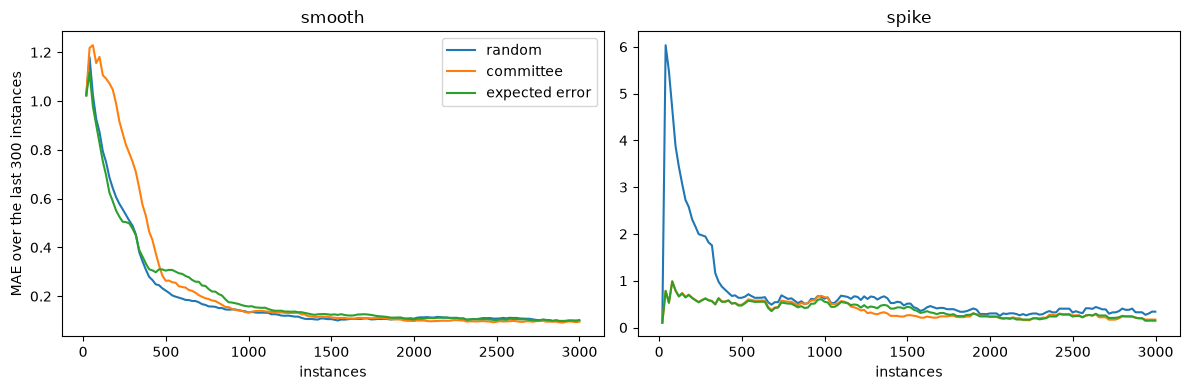

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in make_strategies(seed=0):
    curve = fl.metrics.curve(logs[name, 0], utils.Rolling(metrics.MAE, window_size=300), every=20)
    for ax, output in zip(axes, COSTS):
        c = curve[curve["output"] == output]
        ax.plot(c["step"], c["value"], label=name)
for ax, output in zip(axes, COSTS):
    ax.set(title=output, xlabel="instances")
axes[0].set_ylabel("MAE over the last 300 instances")
axes[0].legend()
fig.tight_layout()

Most of the gap on `spike` comes from the first few hundred instances. With random querying, the
model rarely sees the corner early on, and its errors there are large. Afterwards, the strategies
keep a smaller advantage.

## No free lunch

These strategies help when some instances are more informative than others *and* the model can
make use of them. Here is the stream from the quickstart notebook, with a linear model. The
targets are not linear, so most of the error comes from the model itself, and no choice of
labels can remove it.

In [8]:
OUTPUTS = ["temperature", "pressure", "purity"]
PROCESS_COSTS = {"temperature": 1.0, "pressure": 2.0, "purity": 5.0}


def process_stream(n, seed=42):
    for x, y in datasets.synth.Friedman(seed=seed).take(n):
        yield (
            x,
            {
                "temperature": y,
                "pressure": 10 * x[3] + 5 * x[4],
                "purity": 20 * x[0] * x[1],
            },
        )


def linear():
    return preprocessing.StandardScaler() | linear_model.LinearRegression()


rows = {}
for name, strategy in {
    "random": fl.strategy.RandomPerOutput(p=1.0, seed=0),
    "committee": fl.strategy.QueryByCommittee(linear(), seed=0),
    "expected error": fl.strategy.ExpectedError(linear()),
}.items():
    log = fl.evaluate.prequential(
        process_stream(3000),
        multioutput.RegressorChain(linear(), order=OUTPUTS),
        strategy,
        fl.budget.VariableThreshold(fl.budget.PerOutput(fl.budget.RateBudget(0.5))),
        PROCESS_COSTS,
    )
    rows[name] = {o: m.get() for o, m in fl.metrics.per_output(log, metrics.MAE()).items()}

pd.DataFrame(rows).round(2)

,random,committee,expected error
temperature,3.16,3.08,3.21
pressure,1.36,1.59,2.63
purity,2.52,2.77,2.74


Here neither strategy is a clear win. The committee is slightly better than random querying on
`temperature` and worse on the other outputs. Expected error is worse on all three: it keeps
asking for the instances where the linear model is wrong, but the model cannot fit them anyway,
and it learns from a sample that is no longer representative of the stream.

Whether a strategy is worth it depends on the data and on the model, which is why it should be
evaluated on your own stream before being deployed.